In [1]:
import numpy as np
from scipy.integrate import odeint
from scipy.interpolate import pchip_interpolate
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from scipy.sparse.linalg import spsolve
from scipy.integrate import trapz
from math import atan2, pi, sin, cos, sqrt, exp
import time
from tqdm import tqdm

## System Parameters Setup

In [2]:
class Struct:
    pass

# System parameters (from paper Section 5)
sys = Struct()
sys.ctrl_on = 1  # control on/off switch

# Parameters from the paper
lam_val = 1.0     # lambda(x) = 1
mu_val = 2.0      # mu(x) = 2
q_val = 1.2       # q = 1.2
rho_val = 0.3     # rho = 0.3

# Event-triggered parameters
R_L = 0.2       # Lyapunov-based parameter
zeta = 1.5        # zeta parameter
nu_param = 1.2    # nu parameter

# Simulation parameters
sys.L = 1.0       # spatial domain [0, 1]
sys.T = 15.0      # simulation time 15 s
sys.N = 100       # number of interior spatial points
sys.N_grid = sys.N + 2
sys.N_g = 100     # number of grid points to solve kernels
sys.h = 0.01      # time step
sys.Delta = sys.L / (sys.N + 1)
sys.xspan = np.linspace(0, sys.L, sys.N_grid)
sys.xspanT = sys.xspan[1:-1]  # drop boundaries, length N

print(f"Spatial step: {sys.Delta:.4f}")
print(f"Time step: {sys.h:.4f}")
print(f"Grid points (interior N): {sys.N}")
print(f"xspanT length: {len(sys.xspanT)}")
print(f"Simulation horizon: {sys.T}s")

Spatial step: 0.0099
Time step: 0.0100
Grid points (interior N): 100
xspanT length: 100
Simulation horizon: 15.0s


## System Parameter Functions and Coupling Coefficients

In [3]:
# System parameter functions
fun = Struct()
fun.lam = lambda x: lam_val * np.ones_like(x)  # λ(x) = 1
fun.mu = lambda x: mu_val * np.ones_like(x)    # μ(x) = 2
fun.q = q_val                                   # q = 1.2
fun.rho = rho_val                               # ρ = 0.3
fun.lam_d = lambda x: 0*np.ones_like(x)  # λ'(x) = 0
fun.mu_d = lambda x: 0*np.ones_like(x)  # μ'(x) = 0

# Time- and space-varying coupling coefficients
def sigma_plus(t, x):
    """σ+(t,x) coupling coefficient"""
    return 1 + 0.3 * x * np.exp(2.0*(np.sin(t))**2)

def sigma_minus(t, x):
    """σ-(t,x) coupling coefficient"""
    return 1.0 + 2.0/((np.cosh((t-7)**2))**2) + 0.6*np.cos(np.pi*t) + 2.0/((np.cosh(5*x))**2)

## Kernel Solver (2x2 Block System)

In [4]:
def solver_2x2(params, N_g):
    """Solve the backstepping kernels K and L on the triangular domain."""
    Delta = 1 / (N_g - 1)
    numTot = int(N_g*(N_g + 1) / 2)

    # Map lower-triangular indices to global indices
    index_map = np.zeros((N_g, N_g))
    index_map[np.tril_indices(N_g)] = np.arange(1, numTot+1)
    index_map = np.transpose(index_map)

    dummy1 = np.tril(np.reshape(np.arange(1, (N_g**2)+1), (N_g, N_g))).transpose()
    glob_to_mat = dummy1[dummy1 > 0]
    glob_to_mat = np.array(sorted(glob_to_mat))

    indexes = np.kron(np.arange(1, (2*numTot)+1), np.ones(5)).reshape((2*numTot,5)).astype(int)
    indexes = indexes - 1
    weights = np.zeros((2*numTot, 5))
    RHS = np.zeros((2*numTot, 1))

    # Directional derivatives (characteristics)
    s_K_x, s_K_y = np.meshgrid(params.mu, -params.lam)
    s_L_x, s_L_y = np.meshgrid(params.mu, params.mu)

    s_K = np.sqrt(s_K_x**2 + s_K_y**2)
    s_L = np.sqrt(s_L_x**2 + s_L_y**2)

    # K: iterate over triangular region
    for indX in range(N_g):
        for indY in range(indX+1):
            glob_ind = int(index_map[indY, indX])
            if (indY == indX):
                # boundary condition on the diagonal
                weights[glob_ind-1, 0] = 1
                RHS[glob_ind-1] = params.f[indY]
            else:
                theta = np.arctan2(s_K_x[indY, indX], -s_K_y[indY, indX])
                if theta > np.pi / 4:
                    sigma = Delta / np.sin(theta)
                    d = sigma * np.cos(theta)
                    preFactor = (s_K[indY, indX] / sigma)
                    weights[glob_ind-1, 0] = preFactor
                    weights[glob_ind-1, 1] = -preFactor * d / Delta
                    indexes[glob_ind-1, 1] = int(index_map[indY + 1, indX - 1])-1
                    weights[glob_ind-1, 2] = -preFactor * (Delta - d) / Delta
                    indexes[glob_ind-1, 2] = int(index_map[indY, indX - 1])-1
                else:
                    sigma = Delta / np.cos(theta)
                    d = sigma * np.sin(theta)
                    preFactor = (s_K[indY, indX] / sigma)
                    weights[glob_ind-1, 0] = preFactor
                    weights[glob_ind-1, 1] = -preFactor * d / Delta
                    indexes[glob_ind-1, 1] = int(index_map[indY + 1, indX - 1])-1
                    weights[glob_ind-1, 2] = -preFactor * (Delta - d) / Delta
                    indexes[glob_ind-1, 2] = int(index_map[indY + 1, indX])-1

                # handle near-diagonal correction
                if indY == indX - 1:
                    if theta > np.pi / 4:
                        weights[glob_ind-1, 2] = weights[glob_ind-1, 2] + weights[glob_ind-1, 1]
                        weights[glob_ind-1, 0] = weights[glob_ind-1, 0] - weights[glob_ind-1, 1]
                        indexes[glob_ind-1, 1] = int(index_map[indY + 1, indX])-1
                    else:
                        weights[glob_ind-1, 2] = weights[glob_ind-1, 2] + weights[glob_ind-1, 1]
                        weights[glob_ind-1, 0] = weights[glob_ind-1, 0] - weights[glob_ind-1, 1]
                        indexes[glob_ind-1, 1] = int(index_map[indY, indX - 1])-1
    
    # L: iterate over triangular region
    for indX in range(N_g):
        for indY in range(indX + 1):
            glob_ind = int(index_map[indY, indX]) + numTot
            if indY == 0:
                # boundary condition on the bottom edge
                weights[glob_ind-1, 0] = -1
                weights[glob_ind-1, 1] = params.q
                indexes[glob_ind-1, 1] = glob_ind - numTot - 1
            else:
                theta = np.arctan2(s_L_y[indY, indX], s_L_x[indY, indX])
                if theta < np.pi / 4:
                    sigma = Delta / np.cos(theta)
                    d = sigma * np.sin(theta)
                    preFactor = (s_L[indY, indX] / sigma)
                    weights[glob_ind-1, 0] = preFactor
                    weights[glob_ind-1, 1] = -preFactor * (Delta - d) / Delta
                    indexes[glob_ind-1, 1] = int(index_map[indY, indX - 1]) + numTot - 1
                    weights[glob_ind-1, 2] = -preFactor * d / Delta
                    indexes[glob_ind-1, 2] = int(index_map[indY - 1, indX - 1]) + numTot - 1
                else:
                    sigma = Delta / np.sin(theta)
                    d = sigma * np.cos(theta)
                    preFactor = (s_L[indY, indX] / sigma)
                    weights[glob_ind-1, 0] = preFactor
                    weights[glob_ind-1, 1] = -preFactor * d / Delta
                    indexes[glob_ind-1, 1] = int(index_map[indY - 1, indX - 1]) + numTot - 1
                    weights[glob_ind-1, 2] = -preFactor * (Delta - d) / Delta
                    indexes[glob_ind-1, 2] = int(index_map[indY - 1, indX]) + numTot - 1

    # Source terms coupling K and L blocks
    for indX in range(N_g):
        for indY in range(indX+1):
            glob_ind = int(index_map[indY, indX])
            if indY != indX:
                weights[glob_ind-1, 3] = -params.a_1[indY, indX]
                weights[glob_ind-1, 4] = -params.a_2[indY, indX]
                indexes[glob_ind-1, 4] = glob_ind + numTot - 1

            if indY != 0:
                weights[glob_ind-1+numTot, 3] = -params.b_1[indY, indX]
                indexes[glob_ind-1+numTot, 3] = glob_ind - 1
                weights[glob_ind-1+numTot, 4] = -params.b_2[indY, indX]

    # Assemble sparse system and solve
    counter = 0
    A_coord_x = np.zeros(2*numTot * 5, dtype=int)
    A_coord_y = np.zeros(2*numTot * 5, dtype=int)
    A_vals = np.zeros(2*numTot * 5)
    b_coord_y = np.zeros(2*numTot, dtype=int)
    b_vals = np.zeros(2*numTot)

    for i in range(2*numTot):
        for j in range(5):
            A_coord_y[counter] = i
            A_coord_x[counter] = indexes[i, j]
            A_vals[counter] = weights[i, j]
            counter += 1
        b_coord_y[i] = i
        b_vals[i] = RHS[i][0]

    A = csr_matrix((A_vals, (A_coord_y, A_coord_x)), shape=(2*numTot, 2*numTot))
    b = csr_matrix((b_vals, (b_coord_y, np.zeros(2*numTot))), shape=(2*numTot, 1))

    x = spsolve(A, b)

    K = np.zeros((N_g, N_g))
    L = np.zeros((N_g, N_g))

    K_dummy = x[:numTot]
    L_dummy = x[numTot:2*numTot]

    K[np.tril_indices(N_g)] = K_dummy
    L[np.tril_indices(N_g)] = L_dummy
    K = K.transpose()
    L = L.transpose()

    return K, L

print("Kernel solver defined")

Kernel solver defined


## Compute Kvu and Kvv (Lower-Right Block)

In [5]:
def compute_kernel_at_event(t_event, N_g, fun, q_val, rho_val):
    """
    Compute kernels Kvu and Kvv at event time with frozen σ+(t_event, x) and σ-(t_event, x).
    Returns Kvu and Kvv blocks.
    """
    xspan = np.linspace(0, 1, N_g)
    params = Struct()
    params.mu = fun.mu(xspan)
    params.lam = fun.lam(xspan)
    params.lam_d = fun.lam_d(xspan)
    params.mu_d = fun.mu_d(xspan)
    params.a_1 = np.zeros((N_g, N_g))
    params.a_2 = np.zeros((N_g, N_g))
    params.b_1 = np.zeros((N_g, N_g))
    params.b_2 = np.zeros((N_g, N_g))

    # Use frozen coupling coefficients at t_event
    for i in range(N_g):
        for j in range(N_g):
            params.a_1[i, j] = fun.lam_d(xspan[i])
            params.a_2[i, j] = sigma_minus(t_event, xspan[i])
            params.b_1[i, j] = sigma_plus(t_event, xspan[i])
            params.b_2[i, j] = -fun.mu_d(xspan[i])
    
    # Boundary/source terms
    params.f = -(sigma_minus(t_event, xspan)) / (fun.lam(xspan) + fun.mu(xspan))
    params.q = q_val * fun.lam(0) / fun.mu(0)
    
    Kvu, Kvv = solver_2x2(params, N_g)
    return Kvu, Kvv

print("compute_kernel_at_event (Kvu, Kvv) defined")

compute_kernel_at_event (Kvu, Kvv) defined


## Compute Kuu and Kuv (Upper-Left Block)

In [6]:
def compute_kernel_at_event_firsttwo(t_event, N_g, fun, q_val, rho_val):
    """
    Compute kernels Kuv and Kuu at event time with frozen σ+(t_event, x) and σ-(t_event, x).
    Returns Kuv and Kuu blocks.
    """
    xspan = np.linspace(0, 1, N_g)
    params = Struct()
    params.mu = fun.lam(xspan)
    params.lam = fun.mu(xspan)
    params.lam_d = fun.mu_d(xspan)
    params.mu_d = fun.lam_d(xspan)
    params.a_1 = np.zeros((N_g, N_g))
    params.a_2 = np.zeros((N_g, N_g))
    params.b_1 = np.zeros((N_g, N_g))
    params.b_2 = np.zeros((N_g, N_g))

    # Use frozen coupling coefficients at t_event
    for i in range(N_g):
        for j in range(N_g):
            params.a_1[i, j] = -fun.mu_d(xspan[i])
            params.a_2[i, j] = sigma_plus(t_event, xspan[i])
            params.b_1[i, j] = -sigma_minus(t_event, xspan[i])
            params.b_2[i, j] = -fun.lam_d(xspan[i])
    
    # Boundary/source terms
    params.f = (sigma_plus(t_event, xspan)) / (fun.lam(xspan) + fun.mu(xspan))
    params.q = fun.lam(0) / (fun.mu(0)*q_val)
    
    Kuv, Kuu = solver_2x2(params, N_g)
    return Kuv, Kuu

print("compute_kernel_at_event_firsttwo (Kuv, Kuu) defined")

compute_kernel_at_event_firsttwo (Kuv, Kuu) defined


## Generate Training Data: X_train = (σ⁺, σ⁻), Y_train = (Kuu, Kuv, Kvu, Kvv)

In [7]:
def generate_training_sample_all_kernels(t_event, N_g, fun, q_val, rho_val):
    """
    Generate one training sample with all four kernels:
    Input: (σ⁺(t,x), σ⁻(t,x)) sampled at grid points
    Output: (Kuu, Kuv, Kvu, Kvv) kernels flattened (lower triangular parts)
    """
    xspan = np.linspace(0, 1, N_g)
    
    # Compute all four kernels
    Kvu, Kvv = compute_kernel_at_event(t_event, N_g, fun, q_val, rho_val)
    Kuv, Kuu = compute_kernel_at_event_firsttwo(t_event, N_g, fun, q_val, rho_val)
    
    # Input: sample sigma_plus and sigma_minus on grid
    sigma_plus_vals = sigma_plus(t_event, xspan)
    sigma_minus_vals = sigma_minus(t_event, xspan)
    input_feature = np.hstack([sigma_plus_vals, sigma_minus_vals])  # shape (2*N_g,)
    
    # Output: flatten all four kernels (store only lower triangular parts)
    Kuu_lower = Kuu[np.triu_indices(N_g)]
    Kuv_lower = Kuv[np.triu_indices(N_g)]
    Kvu_lower = Kvu[np.triu_indices(N_g)]
    Kvv_lower = Kvv[np.triu_indices(N_g)]
    output_feature = np.hstack([Kuu_lower, Kuv_lower, Kvu_lower, Kvv_lower])  # shape (4*numTot,)
    
    return input_feature, output_feature, Kuu, Kuv, Kvu, Kvv

print("Training data generation function (all kernels) defined")

Training data generation function (all kernels) defined


## Generate Training Samples (2000 Samples with All Four Kernels)

In [8]:
# Generate training data with all four kernels
num_samples = 2000  # Number of training samples

# Storage for training data
X_train_list = []  # Input: (σ⁺, σ⁻)
Y_train_list = []  # Output: (Kuu, Kuv, Kvu, Kvv)

numTot = int(sys.N_g * (sys.N_g + 1) / 2)
output_size = 4 * numTot  # Four kernels instead of two

print(f"Generating {num_samples} training samples with all four kernels")
print(f"Input size: {2 * sys.N_g} (σ⁺ and σ⁻)")
print(f"Output size: {output_size} (Kuu + Kuv + Kvu + Kvv lower triangular)")
print(f"Each kernel contributes {numTot} elements")

# Generate samples with random time instances
np.random.seed(42)  # For reproducibility

for sample_idx in tqdm(range(num_samples), desc="Generating samples"):
    # Randomly select time points from the simulation horizon
    t_event = np.random.uniform(0, sys.T)
    
    try:
        input_feature, output_feature, _, _, _, _ = generate_training_sample_all_kernels(
            t_event, sys.N_g, fun, q_val, rho_val
        )
        X_train_list.append(input_feature)
        Y_train_list.append(output_feature)
    except Exception as e:
        print(f"Error at sample {sample_idx}: {e}")
        continue

# Convert to numpy arrays
X_train_all = np.array(X_train_list, dtype=np.float32)
Y_train_all = np.array(Y_train_list, dtype=np.float32)

print(f"\nGenerated {len(X_train_all)} valid samples")
print(f"X_train shape: {X_train_all.shape}")
print(f"Y_train shape: {Y_train_all.shape}")

Generating 2000 training samples with all four kernels
Input size: 200 (σ⁺ and σ⁻)
Output size: 20200 (Kuu + Kuv + Kvu + Kvv lower triangular)
Each kernel contributes 5050 elements


Generating samples: 100%|██████████| 2000/2000 [07:13<00:00,  4.62it/s]


Generated 2000 valid samples
X_train shape: (2000, 200)
Y_train shape: (2000, 20200)


## Save Training Data

In [9]:
# Save training data
print("\nSaving training data...")

# Use 80-20 split for training and validation
split_idx = int(0.8 * len(X_train_all))
X_train, X_val = X_train_all[:split_idx], X_train_all[split_idx:]
Y_train, Y_val = Y_train_all[:split_idx], Y_train_all[split_idx:]

np.save('X_train_allkernels.npy', X_train)
np.save('Y_train_allkernels.npy', Y_train)
np.save('X_val_allkernels.npy', X_val)
np.save('Y_val_allkernels.npy', Y_val)

print(f"✓ X_train_allkernels.npy saved: shape {X_train.shape}")
print(f"✓ Y_train_allkernels.npy saved: shape {Y_train.shape}")
print(f"✓ X_val_allkernels.npy saved: shape {X_val.shape}")
print(f"✓ Y_val_allkernels.npy saved: shape {Y_val.shape}")

print(f"\nTraining set: {len(X_train)} samples")
print(f"Validation set: {len(X_val)} samples")
print(f"\nKernel breakdown in Y_train:")
print(f"  Kuu: indices 0 to {numTot-1}")
print(f"  Kuv: indices {numTot} to {2*numTot-1}")
print(f"  Kvu: indices {2*numTot} to {3*numTot-1}")
print(f"  Kvv: indices {3*numTot} to {4*numTot-1}")


Saving training data...
✓ X_train_allkernels.npy saved: shape (1600, 200)
✓ Y_train_allkernels.npy saved: shape (1600, 20200)
✓ X_val_allkernels.npy saved: shape (400, 200)
✓ Y_val_allkernels.npy saved: shape (400, 20200)

Training set: 1600 samples
Validation set: 400 samples

Kernel breakdown in Y_train:
  Kuu: indices 0 to 5049
  Kuv: indices 5050 to 10099
  Kvu: indices 10100 to 15149
  Kvv: indices 15150 to 20199


## Visualize Sample Kernels (All Four Blocks)

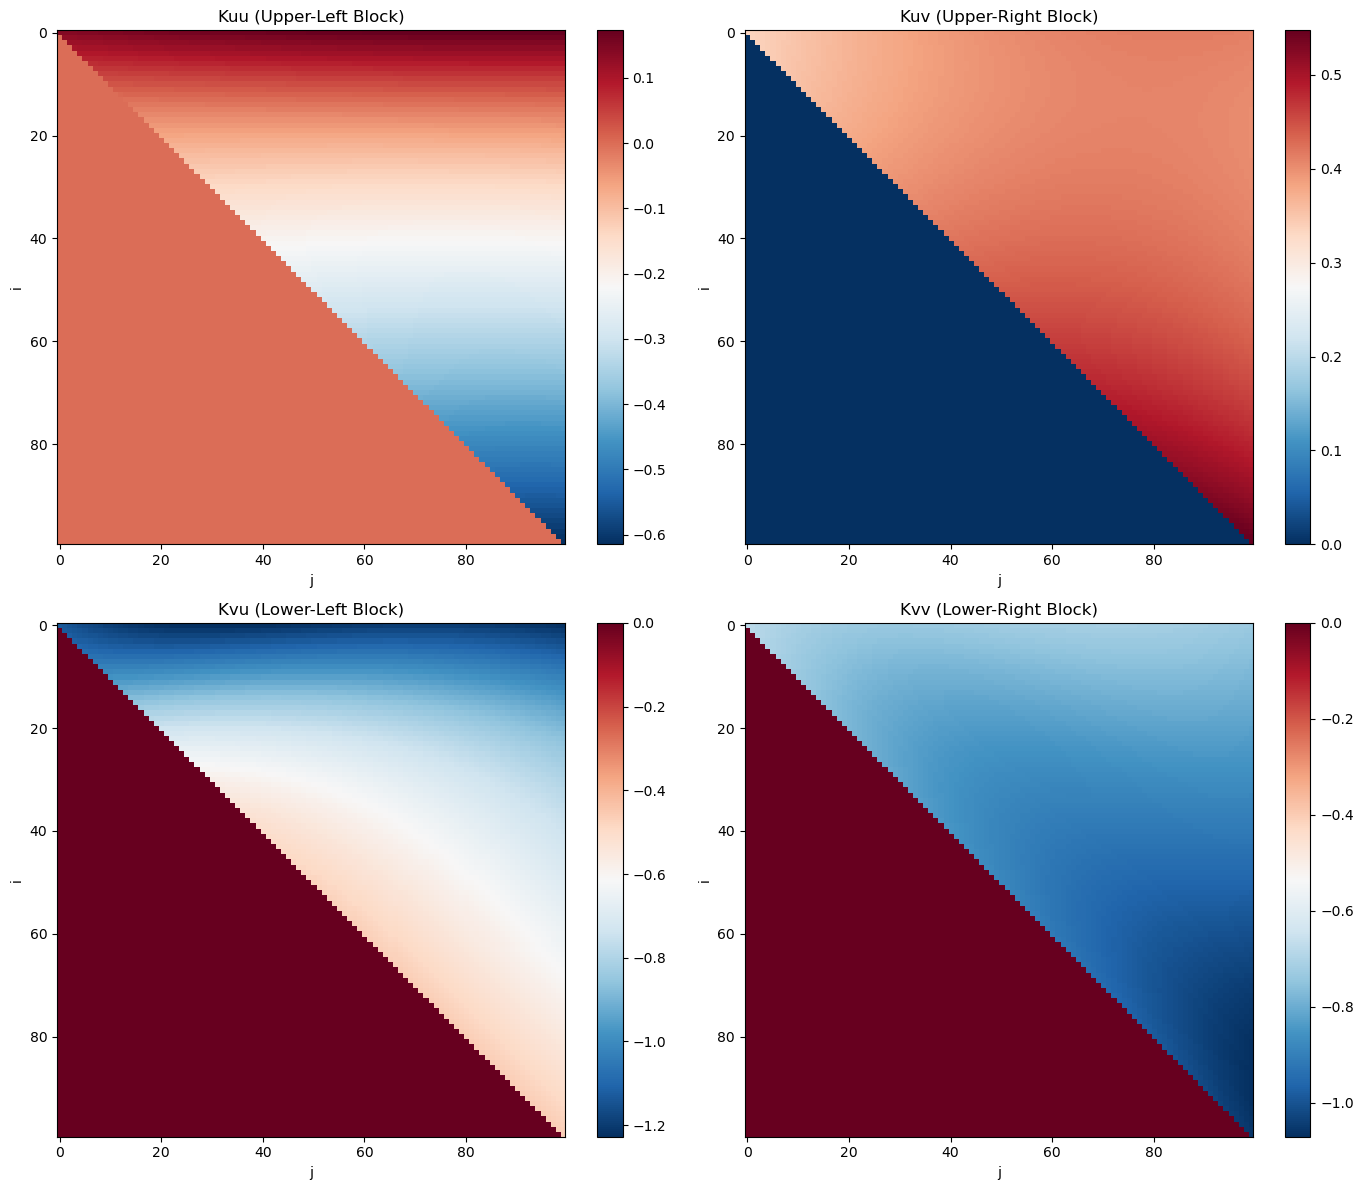

Visualized sample 0 with all four kernel blocks


In [10]:
# Visualize a sample with all four kernels
sample_idx = 0

# Reconstruct all four kernels from flattened output
Kuu_mat = np.zeros((sys.N_g, sys.N_g))
Kuv_mat = np.zeros((sys.N_g, sys.N_g))
Kvu_mat = np.zeros((sys.N_g, sys.N_g))
Kvv_mat = np.zeros((sys.N_g, sys.N_g))

Y_sample = Y_train[sample_idx]

# Extract each kernel block
Kuu_lower = Y_sample[:numTot]
Kuv_lower = Y_sample[numTot:2*numTot]
Kvu_lower = Y_sample[2*numTot:3*numTot]
Kvv_lower = Y_sample[3*numTot:4*numTot]

# Reconstruct from lower triangular
Kuu_mat[np.triu_indices(sys.N_g)] = Kuu_lower
Kuv_mat[np.triu_indices(sys.N_g)] = Kuv_lower
Kvu_mat[np.triu_indices(sys.N_g)] = Kvu_lower
Kvv_mat[np.triu_indices(sys.N_g)] = Kvv_lower

# Plot all four kernels
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

im1 = axes[0, 0].imshow(Kuu_mat, cmap='RdBu_r', aspect='auto')
axes[0, 0].set_title('Kuu (Upper-Left Block)', fontsize=12)
axes[0, 0].set_xlabel('j')
axes[0, 0].set_ylabel('i')
plt.colorbar(im1, ax=axes[0, 0])

im2 = axes[0, 1].imshow(Kuv_mat, cmap='RdBu_r', aspect='auto')
axes[0, 1].set_title('Kuv (Upper-Right Block)', fontsize=12)
axes[0, 1].set_xlabel('j')
axes[0, 1].set_ylabel('i')
plt.colorbar(im2, ax=axes[0, 1])

im3 = axes[1, 0].imshow(Kvu_mat, cmap='RdBu_r', aspect='auto')
axes[1, 0].set_title('Kvu (Lower-Left Block)', fontsize=12)
axes[1, 0].set_xlabel('j')
axes[1, 0].set_ylabel('i')
plt.colorbar(im3, ax=axes[1, 0])

im4 = axes[1, 1].imshow(Kvv_mat, cmap='RdBu_r', aspect='auto')
axes[1, 1].set_title('Kvv (Lower-Right Block)', fontsize=12)
axes[1, 1].set_xlabel('j')
axes[1, 1].set_ylabel('i')
plt.colorbar(im4, ax=axes[1, 1])

plt.tight_layout()
plt.show()

print(f"Visualized sample {sample_idx} with all four kernel blocks")

## Statistics Summary

In [11]:
print("="*80)
print("TRAINING DATA SUMMARY")
print("="*80)
print(f"\nTotal samples: {len(X_train_all)}")
print(f"Training samples: {len(X_train)}")
print(f"Validation samples: {len(X_val)}")
print(f"\nInput dimension: {X_train.shape[1]} (2 × {sys.N_g} grid points)")
print(f"Output dimension: {Y_train.shape[1]} (4 × {numTot} kernel elements)")
print(f"\nKernel grid: {sys.N_g} × {sys.N_g}")
print(f"Lower triangular size per kernel: {numTot}")
print(f"\nOutput breakdown:")
print(f"  Kuu: {numTot} elements")
print(f"  Kuv: {numTot} elements")
print(f"  Kvu: {numTot} elements")
print(f"  Kvv: {numTot} elements")
print(f"  Total: {4*numTot} elements")
print("\n" + "="*80)

TRAINING DATA SUMMARY

Total samples: 2000
Training samples: 1600
Validation samples: 400

Input dimension: 200 (2 × 100 grid points)
Output dimension: 20200 (4 × 5050 kernel elements)

Kernel grid: 100 × 100
Lower triangular size per kernel: 5050

Output breakdown:
  Kuu: 5050 elements
  Kuv: 5050 elements
  Kvu: 5050 elements
  Kvv: 5050 elements
  Total: 20200 elements

